# QPUTwin quickstart

QPUTwin runs digital twins of four quantum processors as a cloud service. You send OpenQASM over HTTP, and each twin
compiles it to that device's native gates, applies its noise model, simulates it and returns counts with a full report.

Every job in these notebooks goes through the API to the Docker stack. Start the stack from the project root first:

```bash
docker compose up -d --wait
```

In [1]:
from qputwin_demo import *

connect()
backends()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


,id,status,vendor,technology,n_physical,connectivity,calibration
0,google_willow,online,Google,superconducting,105,nearest_neighbour,Google Willow - willow_pink calibration snapshot
1,ibm_heron,online,IBM,superconducting,156,nearest_neighbour,IBM Heron r3 - ibm_boston calibration snapshot
2,ibm_nighthawk,online,IBM,superconducting,120,nearest_neighbour,IBM Nighthawk r1 - ibm_miami calibration snapshot
3,ionq_forte,online,IonQ,trapped_ion,36,all_to_all,IonQ Forte - nominal medians
4,iqm_emerald,online,IQM,superconducting,54,nearest_neighbour,IQM Emerald - nominal medians
5,quantinuum_helios,online,Quantinuum,trapped_ion,98,all_to_all,Quantinuum Helios - nominal medians
6,rigetti_ankaa_3,online,Rigetti,superconducting,84,nearest_neighbour,Rigetti Ankaa-3 - nominal medians


## Your first circuit

A Bell pair is the smallest entangled circuit: a Hadamard, then a CNOT. The result should be `00` and `11`, half each.

OPENQASM 2.0;
include "qelib1.inc";
qreg q[2];
creg c[2];
h q[0];
cx q[0],q[1];
measure q -> c;



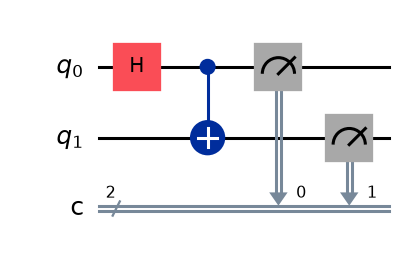

In [2]:
circuit = bell()
print(circuit)
draw(circuit)

## Run it on a twin

One function call is one `POST /v1/jobs`.

HTTP status: 200
Job id:      a4555dbb08a84864b62255d441c3c9d0
Counts:      {'00': 515, '11': 509}


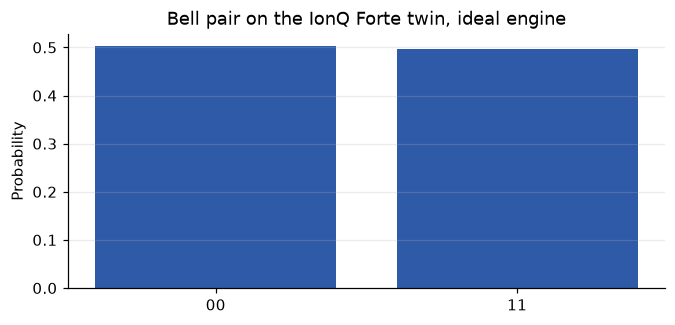

In [3]:
result = run("ionq_forte", circuit, shots=1024, seed=42)

print("HTTP status:", result["http_status"])
print("Job id:     ", result["job_id"])
print("Counts:     ", result["result"]["counts"])
plot_counts(result["result"]["counts"], "Bell pair on the IonQ Forte twin, ideal engine");

## What came back

The response holds more than counts. `compilation` reports what the circuit became on this device, and `telemetry`
reports where the time went.

In [4]:
print("Top-level keys:", list(result))

compilation = result["compilation"]
pd.Series({
    "Input gates": compilation["input_gate_count"],
    "Native gates used": compilation["native_gate_histogram"],
    "Two-qubit depth": compilation["two_qubit_depth"],
    "Compilation error": compilation["max_synthesis_error"],
    "Estimated hardware time (µs)": compilation["hardware_time_estimate"]["circuit_duration_us"],
    "Round trip (ms)": round(result["telemetry"]["total_roundtrip_ms"], 2),
    "Engine": result["telemetry"]["workload"]["engine"],
}).to_frame("value")

Top-level keys: ['job_id', 'backend', 'status', 'result', 'compilation', 'telemetry', 'http_status']


,value
Input gates,2
Native gates used,"{'gpi2': 2, 'ms': 1, 'rz': 1}"
Two-qubit depth,1
Compilation error,0.0
Estimated hardware time (µs),1035.0
Round trip (ms),5.95
Engine,statevector


## Reproducible by seed

The same seed gives the same counts, on any run. This is what makes a re-executed job safe later in these notebooks.

In [5]:
first = run("ionq_forte", circuit, seed=2026)["result"]["counts"]
second = run("ionq_forte", circuit, seed=2026)["result"]["counts"]
other = run("ionq_forte", circuit, seed=2027)["result"]["counts"]

print("seed 2026:", first)
print("seed 2026:", second, "(identical)" if first == second else "(DIFFERENT)")
print("seed 2027:", other)

seed 2026: {'00': 474, '11': 550}
seed 2026: {'00': 474, '11': 550} (identical)
seed 2027: {'00': 510, '11': 514}


## The same circuit on every twin, with noise

`noise=True` applies each device's calibrated noise model. A five-qubit GHZ state should give only `00000` and `11111`.
Other outcomes are the errors each device is expected to make.

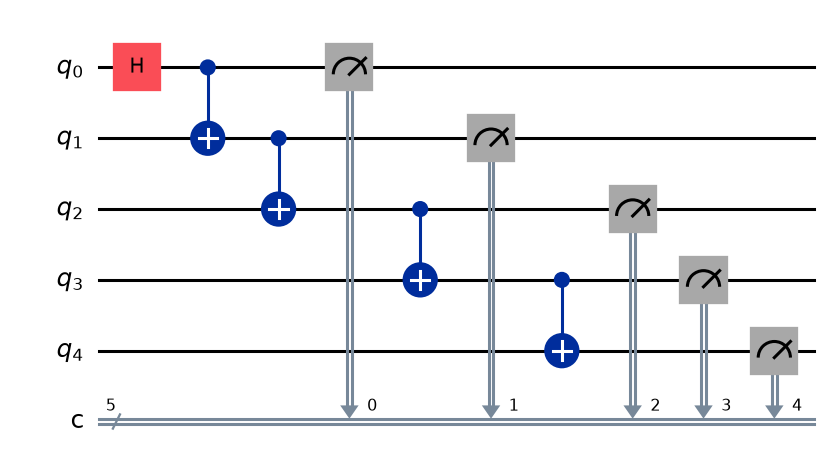

In [6]:
circuit = ghz(5)
draw(circuit)

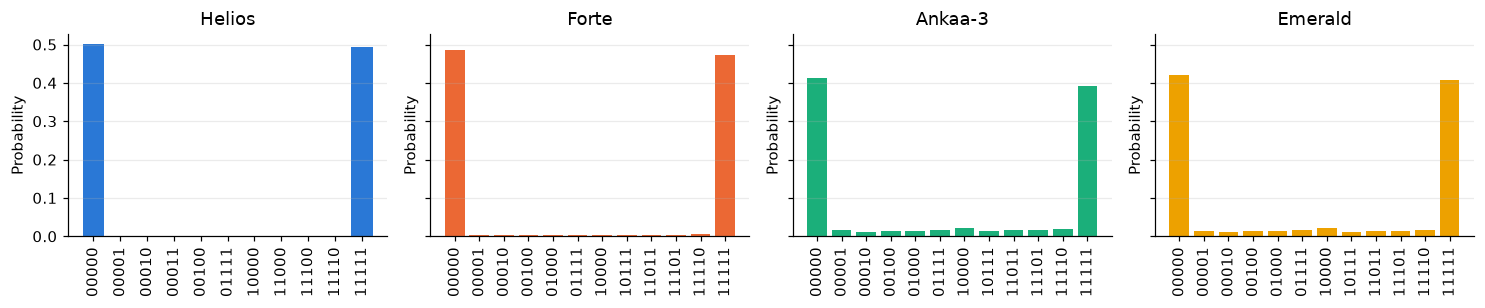

,P(00000 or 11111),Native two-qubit gates,Estimated shot time (µs)
Helios,0.996,4.0,600.000
Forte,0.958,4.0,3240.000
Ankaa-3,0.806,4.0,1.988
Emerald,0.827,4.0,1.940


In [7]:
results = {backend: run(backend, circuit, noise=True, shots=4096) for backend in BACKENDS}
plot_each_twin(results)

pd.DataFrame({NAMES[b]: {
    "P(00000 or 11111)": round(success(r, ["00000", "11111"]), 3),
    "Native two-qubit gates": r["compilation"]["native_two_qubit_count"],
    "Estimated shot time (µs)": r["compilation"]["hardware_time_estimate"]["circuit_duration_us"],
} for b, r in results.items()}).T

The next notebooks open up each step: devices, compilation, noise, routing, algorithms, the job service, telemetry and
fault tolerance.